In [23]:
# 準備：ライブラリ、日本語フォント、テキストデータをまとめて用意する（最初に1回だけ実行する）
# 2〜3分かかります。途中で WARNING などが表示されても、最後に「準備完了」と表示されれば大丈夫です。

# ライブラリのインストール
!pip install -q numpy spacy ginza ja-ginza scikit-learn pandas wordcloud networkx pyvis matplotlib-fontja altair

# 英語のモデルのダウンロード
!python -m spacy download en_core_web_sm -q

# 日本語フォントのインストール（ワードクラウド用）
!apt-get -qq update > /dev/null
!apt-get -qq install -y fonts-ipaexfont > /dev/null


# 確認：モデル、フォント、テキストがそろっていれば「準備完了」と表示される
import os
import spacy

spacy.load("ja_ginza")
spacy.load("en_core_web_sm")
if os.path.exists("/usr/share/fonts/opentype/ipaexfont-gothic/ipaexg.ttf") and os.path.exists("text/sanshiro.txt"):
    print("準備完了")
else:
    print("フォントかテキストが見つかりません。このセルをもう一度実行してください。")


[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
�w�肳�ꂽ�p�X��������܂���B
�w�肳�ꂽ�p�X��������܂���B


フォントかテキストが見つかりません。このセルをもう一度実行してください。


In [24]:
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer

In [25]:
def process_in_batches(input_file, output_file, nlp, batch_size=100):
    all_tokens = []
    lines = []
    count = 0

    with open(input_file, "r", encoding="utf-8") as fin, \
         open(output_file, "w", encoding="utf-8") as fout:

        for line in fin:
            if len(line.strip()) == 0:  # 空行はスキップ
                continue

            lines.append(line.rstrip())
            count += 1

            # バッチサイズに達したら処理
            if count % batch_size == 0:
                docs = nlp.pipe(lines)
                for doc in docs:
                    tokens = [token.text for token in doc]
                    fout.write(' '.join(tokens) + "\n")
                    all_tokens.extend([token for token in doc])
                lines = []  # リストをクリア

        # 残りの行を処理
        if lines:
            docs = nlp.pipe(lines)
            for doc in docs:
                tokens = [token.text for token in doc]
                fout.write(' '.join(tokens) + "\n")
                all_tokens.extend([token for token in doc])

    return all_tokens

In [26]:
input_fn = "../ocred_txt/waseda/2024/part1.txt"
output_fn = "../ocred_txt/waseda/2024/part1_wakati.txt"
input_fn="../ocred_txt/kyotu/2024.txt"
output_fn="../ocred_txt/kyotu/2024_wakati.txt"
nlp = spacy.load("en_core_web_sm", disable=["ner"])
all_tokens = process_in_batches(input_fn, output_fn, nlp)
stopwords=()

In [27]:
from collections import Counter

include_pos = ("NOUN", "VERB", "ADJ")
counter = Counter(token.lemma_ for token in all_tokens if token.pos_ in include_pos and token.lemma_ )
# 出現頻度top 20を出力する
for word, count in counter.most_common(20):
    print(f"{count:>5} {word}")

   42 have
   37 time
   18 people
   17 make
   16 do
   16 pepper
   15 use
   14 see
   14 food
   13 call
   12 chili
   11 think
   11 say
   11 ask
   11 eat
   10 school
   10 other
   10 become
    9 day
    9 go


In [28]:
def extract_words(sent, pos_tags, stopwords):
    """
    分析対象の品詞であり、不要語ではない単語を抽出する
    """
    if len(pos_tags) == 0:
        words = [token.lemma_ for token in sent if token.lemma_ not in stopwords]
    else:
        words = [token.lemma_ for token in sent if token.pos_ in pos_tags and token.lemma_ not in stopwords]
    return words

In [29]:
def count_cooccurrence(sents, token_length="{2,}"):
    """
    同じ文中に共起する単語を行列形式で列挙する
    """
    token_pattern = f"\\b\\w{token_length}\\b"
    count_model = CountVectorizer(token_pattern=token_pattern)

    X = count_model.fit_transform(sents)
    words = count_model.get_feature_names_out()
    word_counts = np.asarray(X.sum(axis=0)).reshape(-1)

    X[X > 0] = 1 # 同じ共起が2以上出現しても1とする
    Xc = (X.T * X) # 共起行列を求めるための掛け算をする、csr形式の疎行列

    return words, word_counts, Xc, X

In [30]:
def find_sentence_by_cooccurrence(X, idxs):
    """
    指定された共起を含む文を見つける
    """
    occur_flags = (X[:, idxs[0]] > 0)
    for idx in idxs[1:]:
        occur_flags = occur_flags.multiply(X[:, idx] > 0)

    return occur_flags.nonzero()[0]

In [31]:
def process_sentences_in_batches(input_file, nlp, include_pos=[], stopwords=[], batch_size=100, is_lemmatized=True):
    sents = []
    lines = []
    count = 0

    with open(input_file, "r", encoding="utf-8") as f:
        for line in f:
            if len(line.strip()) == 0:  # 空行はスキップ
                continue

            lines.append(line.rstrip())
            count += 1

            # バッチサイズに達したら処理
            if count % batch_size == 0:
                docs = nlp.pipe(lines)
                for doc in docs:
                    if is_lemmatized:
                        batch_sents = [' '.join(extract_words(sent, include_pos, stopwords))
                                    for sent in doc.sents]
                        sents.extend(batch_sents)
                    else:
                        sents.extend(list(doc.sents))
                lines = []  # リストをクリア

        # 残りの行を処理
        if lines:
            docs = nlp.pipe(lines)
            for doc in docs:
                if is_lemmatized:
                    batch_sents = [' '.join(extract_words(sent, include_pos, stopwords))
                                for sent in doc.sents]
                    sents.extend(batch_sents)
                else:
                    sents.extend(list(doc.sents))
    return sents
# 元の文章がCats eat fresh fish. Dogs like meat.なら
# 返り値はsents = [
#    "cat eat fresh fish",
#    "dog like meat"
#]

In [32]:
import networkx as nx
from pyvis.network import Network
import matplotlib_fontja

## 一文ごとの動詞数

入力txt全体を解析して文に分割し、空白・改行を除いて3トークン以上ある文を抽出します。ピリオドなどの句読点もトークン数に含めます。早稲田・共通テストとも同じ条件を適用します。

`VERB` のトークン数を数え、`sentence`（文）と `verb_count`（動詞数）の2列を持つDataFrameで返します。助動詞として判定された `AUX` は集計対象外です。文の区切りと品詞はspaCyの推定結果を使います。

In [33]:
from pathlib import Path
import pandas as pd
import spacy


def count_verbs_per_sentence(input_file):
    """UTF-8のtxtを読み込み、一文ごとの本文と動詞数を返す。"""
    text = Path(input_file).read_text(encoding="utf-8")
    nlp = spacy.load("en_core_web_sm")
    doc = nlp(text)
    sentences = [
        sentence for sentence in doc.sents
        if sum(not token.is_space for token in sentence) > 3
    ]
    results = []

    for sentence in sentences:
        verb_count = sum(token.pos_ in ["VERB"] for token in sentence)
        results.append({
            "sentence": sentence.text.strip(),
            "verb_count": verb_count,
        })

    df = pd.DataFrame(results, columns=["sentence", "verb_count"])
    df["verb_count_ratio"] = df["verb_count"] / len(df)
    return df

In [34]:
year=[2024,2025,2026]
print(year[0])

2024


In [35]:
housei=[]
keio=[]
kyotu=[]
nitidai=[]
waseda=[]
for i in range(3):
    year=[2024,2025,2026]
    housei.append(count_verbs_per_sentence(f"../ocred_txt/housei/{year[i]}_english.txt"))
    keio.append(count_verbs_per_sentence(f"../ocred_txt/keio/{year[i]}_english.txt"))
    kyotu.append(count_verbs_per_sentence(f"../ocred_txt/kyotu/{year[i]}_english.txt"))
    nitidai.append(count_verbs_per_sentence(f"../ocred_txt/nitidai/{year[i]}_english.txt"))
    waseda.append(count_verbs_per_sentence(f"../ocred_txt/waseda/{year[i]}_english.txt"))
kyotu[0]

,sentence,verb_count,verb_count_ratio
0,The Thorpe English Language School (TELS)\nis ...,1,0.003521
1,TELS students don’t need to pay the entrance fee.,2,0.007042
2,Please\npresent your student ID at the recepti...,1,0.003521
3,Have you ever tasted hummus from the Middle Ea...,1,0.003521
4,Couscous from North Africa?,0,0.000000
...,...,...,...
279,People who have eaten several of\nthe world’s ...,3,0.010563
280,"Ghost peppers, which contain one million SHUs,...",3,0.010563
281,Luckily the discomfort some people feeler eati...,3,0.010563
282,"Despite some negative side effects,\nspicy foo...",2,0.007042


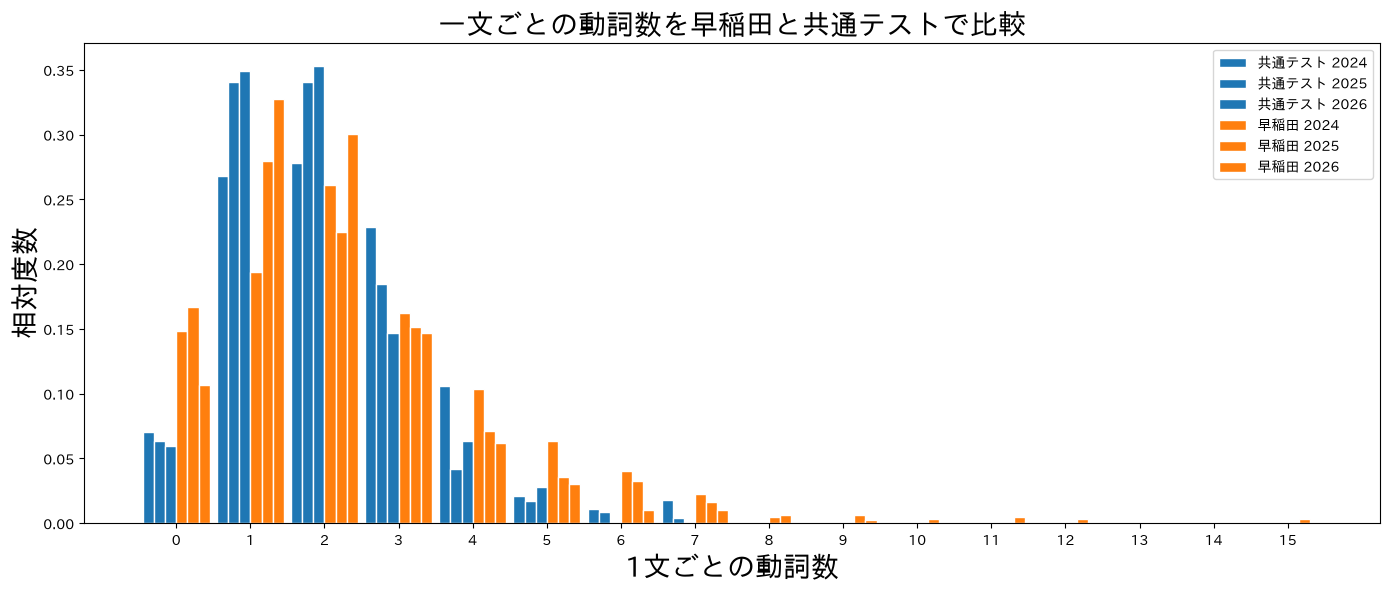

In [36]:
import numpy as np
import matplotlib.pyplot as plt

datasets = kyotu + waseda
labels = ["共通テスト 2024", "共通テスト 2025", "共通テスト 2026",
          "早稲田 2024", "早稲田 2025", "早稲田 2026"]
colors = ["tab:blue"] * 3 + ["tab:orange"] * 3

values = [df["verb_count"] for df in datasets]
weights = [np.ones(len(df)) / len(df) for df in datasets]
max_count = max(df["verb_count"].max() for df in datasets)
bins = np.arange(-0.5, max_count + 1.5, 1)

fig, ax = plt.subplots(figsize=(14, 6))
ax.hist(
    values,
    bins=bins,
    weights=weights,
    color=colors,
    label=labels,
    histtype="bar",
    rwidth=0.9,
    edgecolor="white",
)
ax.set_xticks(np.arange(0, max_count + 1))
ax.set_xlabel("1文ごとの動詞数",fontsize=20)
ax.set_ylabel("相対度数",fontsize=20)
ax.set_title("一文ごとの動詞数を早稲田と共通テストで比較",fontsize=20)
ax.legend()
plt.tight_layout()
plt.show()


In [37]:
for i in range(3):
    year=[2024,2025,2026]
    housei[i]["univ_name"]="housei"
    keio[i]["univ_name"]="keio"
    kyotu[i]["univ_name"]="kyotu"
    nitidai[i]["univ_name"]="nitidai"
    waseda[i]["univ_name"]="waseda"

    housei[i]["year"]=year[i]
    keio[i]["year"]=year[i]
    kyotu[i]["year"]=year[i]
    nitidai[i]["year"]=year[i]
    waseda[i]["year"]=year[i]

df_kakomon=pd.concat([housei[0],housei[1],housei[2]])
for i in range(3):
    df_kakomon=pd.concat([df_kakomon,keio[i],kyotu[i],nitidai[i],waseda[i]])
df_kakomon

,sentence,verb_count,verb_count_ratio,univ_name,year
0,1 Have you heard the news that another typhoon...,4,0.013746,housei,2024
1,constructs\ncomposes\n2\\nrefines\nrefers to\n...,3,0.010309,housei,2024
2,thrilled\nexciting\nlooking forward\nused\n4 T...,7,0.024055,housei,2024
3,take over\nserve\n2\\nwait\ncollect\n6 The con...,14,0.048110,housei,2024
4,work\nhand out\nturn in\nplace\n9 Tokyo is no ...,0,0.000000,housei,2024
...,...,...,...,...,...
398,(6) More than half of the runners in each grou...,2,0.004963,waseda,2026
399,This implies that people may maintain better p...,2,0.004963,waseda,2026
400,@\nThe effectiveness of the new shoe was most ...,1,0.002481,waseda,2026
401,Advanced\nequipment can contribute to enjoying...,3,0.007444,waseda,2026


In [38]:
import plotly.graph_objects as go

# Compute the minimum, quartiles, and maximum for each university and year.
label_name = {"housei": "法政", "keio": "慶應", "kyotu": "共通テスト",
              "nitidai": "日大", "waseda": "早稲田"}
box_stats = (
    df_kakomon.groupby(["univ_name", "year"])["verb_count"]
    .agg(
        minimum="min",
        q1=lambda values: values.quantile(0.25),
        median="median",
        q3=lambda values: values.quantile(0.75),
        maximum="max",
    )
    .reset_index()
)

fig = go.Figure()
for year in sorted(box_stats["year"].unique()):
    stats = box_stats[box_stats["year"] == year]
    fig.add_trace(go.Box(
        name=f"{year}年",
        x=stats["univ_name"].map(label_name),
        q1=stats["q1"],
        median=stats["median"],
        q3=stats["q3"],
        lowerfence=stats["minimum"],
        upperfence=stats["maximum"],
        boxpoints=False,
    ))

fig.update_layout(boxmode="group", xaxis_title="大学・試験", yaxis_title="1文ごとの動詞数", legend_title_text="年度")
fig.show()


In [39]:
df_kakomon_2=df_kakomon[df_kakomon["verb_count"]>3]

In [40]:

# Compute the minimum, quartiles, and maximum for each university and year.
box_stats = (
    df_kakomon_2.groupby(["univ_name", "year"])["verb_count"]
    .agg(
        minimum="min",
        q1=lambda values: values.quantile(0.25),
        median="median",
        q3=lambda values: values.quantile(0.75),
        maximum="max",
    )
    .reset_index()
)

fig = go.Figure()
for year in sorted(box_stats["year"].unique()):
    stats = box_stats[box_stats["year"] == year]
    fig.add_trace(go.Box(
        name=f"{year}年",
        x=stats["univ_name"].map(label_name),
        q1=stats["q1"],
        median=stats["median"],
        q3=stats["q3"],
        lowerfence=stats["minimum"],
        upperfence=stats["maximum"],
        boxpoints=False,
    ))

fig.update_layout(boxmode="group", xaxis_title="大学・試験", yaxis_title="1文ごとの動詞数", legend_title_text="年度")
fig.show()


In [44]:
df_kakomon_2[(df_kakomon_2["univ_name"]=="nitidai")&(df_kakomon_2["verb_count"]==10)]

,sentence,verb_count,verb_count_ratio,univ_name,year
33,When\nWhat\nWho\nHow\n⑪\ncame\ncarried\ncrashe...,10,0.061350,nitidai,2024
1,would have got\nwouldnt have got\nwould get\nh...,10,0.072993,nitidai,2026
